# Presidential model

In [1]:
import sys, json
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
from model.president import config as C, data as D, economy as E, fundamentals as F, uncertainty as U, run as R
from model.president.plots import STYLE, REPLICATION, SILVER, ACTUAL, LIGHT, GREY, figure, dates, bar_labels, identity
plt.rcParams.update(STYLE)
OUT, CY = C.OUT, [2024, 2020]
NAME = {2024: "2024: Harris vs Trump", 2020: "2020: Biden vs Trump"}
SWING = ["PA", "MI", "WI", "GA", "NC", "AZ", "NV"]
ts = {c: pd.read_csv(OUT / str(c) / "timeseries.csv", parse_dates=["date"]) for c in CY}
tss = {c: pd.read_csv(OUT / str(c) / "timeseries_states.csv", parse_dates=["date"]) for c in CY}
eday = {c: pd.read_csv(OUT / str(c) / C.ELECTION_DAYS[c] / "states.csv", index_col=0) for c in CY}
summ = {c: json.load(open(OUT / str(c) / C.ELECTION_DAYS[c] / "summary.json")) for c in CY}
silver = {c: R.silver_outputs(c) for c in CY}
actual = {c: D.actual_results(c) for c in CY}

def silver_window(c, df):
    t = ts[c]
    return df[(df.date >= t.date.min() - pd.Timedelta(days=2)) & (df.date <= t.date.max())]

## 1. Forecast over time

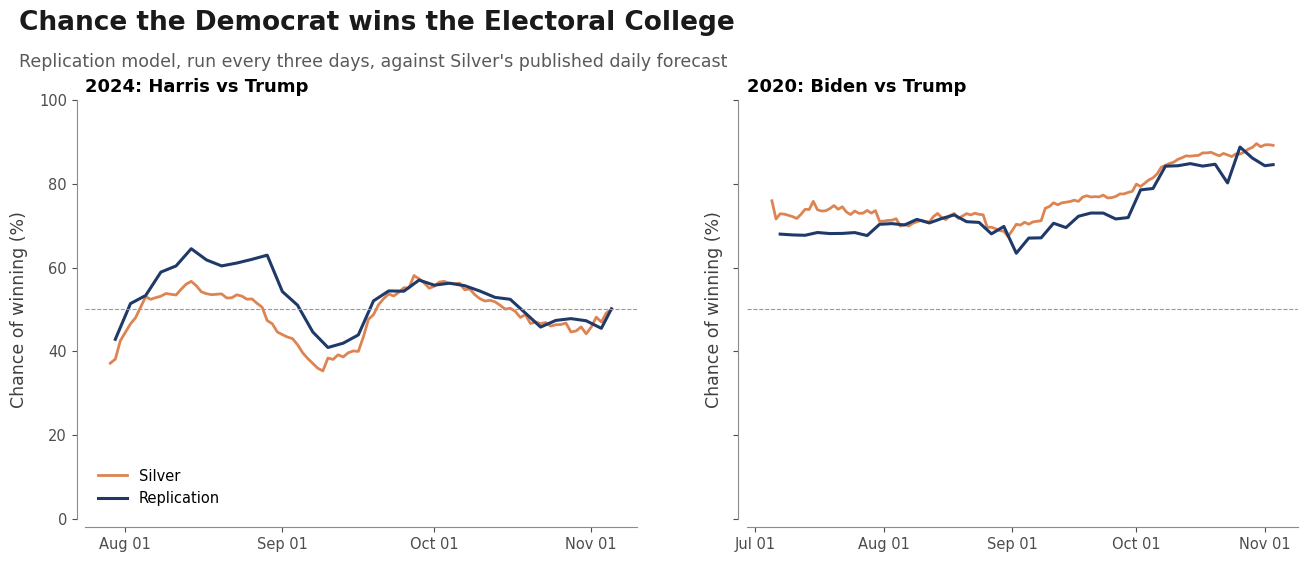

In [2]:
fig, axes = figure("Chance the Democrat wins the Electoral College",
                   "Replication model, run every three days, against Silver's published daily forecast", ncols=2, sharey=True)
for ax, c in zip(axes, CY):
    sn = silver_window(c, silver[c][0])
    ax.plot(sn.date, 100 * sn.win_D, color=SILVER, lw=2, label="Silver")
    ax.plot(ts[c].date, 100 * ts[c].win_D, color=REPLICATION, lw=2.2, label="Replication")
    ax.axhline(50, color=GREY, lw=0.8, ls="--")
    ax.set_title(NAME[c]); ax.set_ylim(0, 100); ax.set_ylabel("Chance of winning (%)"); dates(ax)
axes[0].legend(loc="lower left")
plt.show()

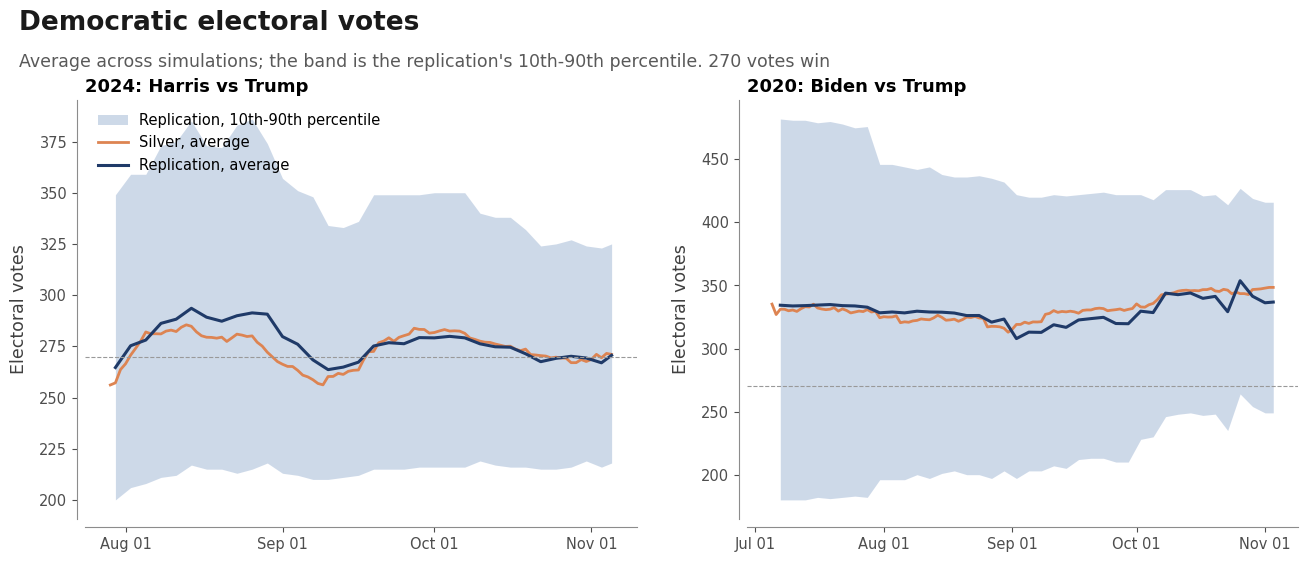

In [3]:
fig, axes = figure("Democratic electoral votes",
                   "Average across simulations; the band is the replication's 10th-90th percentile. 270 votes win", ncols=2)
for ax, c in zip(axes, CY):
    sn = silver_window(c, silver[c][0])
    ax.fill_between(ts[c].date, ts[c].ev_D_p10, ts[c].ev_D_p90, color=LIGHT, alpha=0.5, lw=0, label="Replication, 10th-90th percentile")
    ax.plot(sn.date, sn.ev_D, color=SILVER, lw=2, label="Silver, average")
    ax.plot(ts[c].date, ts[c].ev_D, color=REPLICATION, lw=2.2, label="Replication, average")
    ax.axhline(270, color=GREY, lw=0.8, ls="--")
    ax.set_title(NAME[c]); ax.set_ylabel("Electoral votes"); dates(ax)
axes[0].legend(loc="upper left")
plt.show()

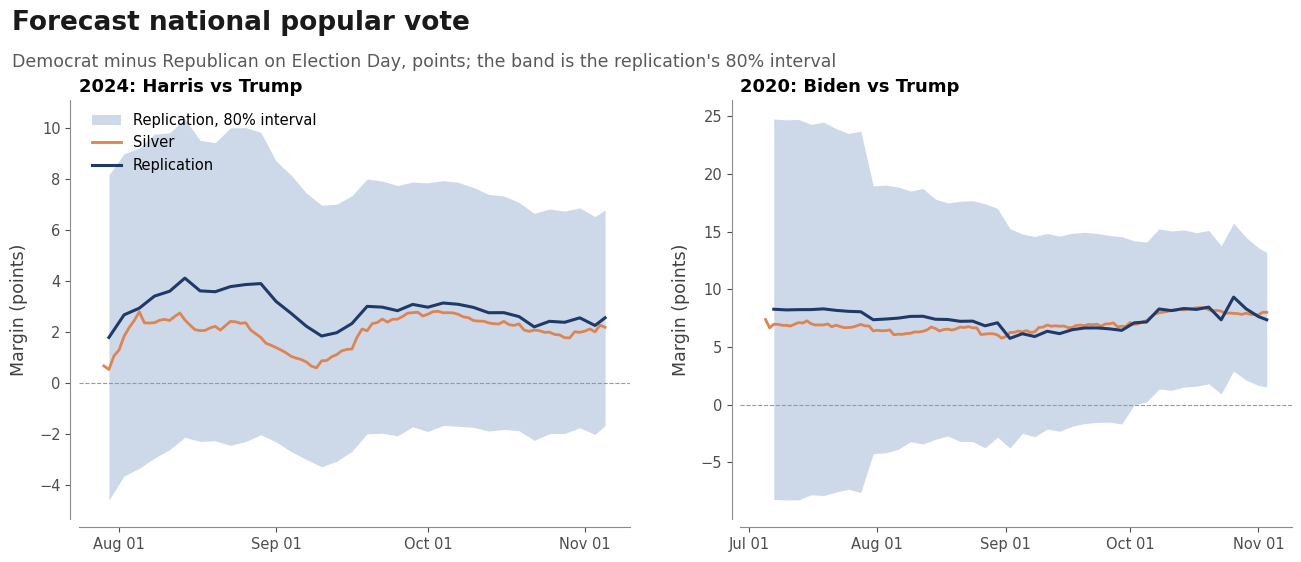

In [4]:
fig, axes = figure("Forecast national popular vote",
                   "Democrat minus Republican on Election Day, points; the band is the replication's 80% interval", ncols=2)
for ax, c in zip(axes, CY):
    sn, t = silver_window(c, silver[c][0]), ts[c]
    ax.fill_between(t.date, t.popvote_margin - 1.28 * t.popvote_margin_sd, t.popvote_margin + 1.28 * t.popvote_margin_sd,
                    color=LIGHT, alpha=0.5, lw=0, label="Replication, 80% interval")
    ax.plot(sn.date, sn.popvote_margin, color=SILVER, lw=2, label="Silver")
    ax.plot(t.date, t.popvote_margin, color=REPLICATION, lw=2.2, label="Replication")
    ax.axhline(0, color=GREY, lw=0.8, ls="--")
    ax.set_title(NAME[c]); ax.set_ylabel("Margin (points)"); dates(ax)
axes[0].legend(loc="upper left")
plt.show()

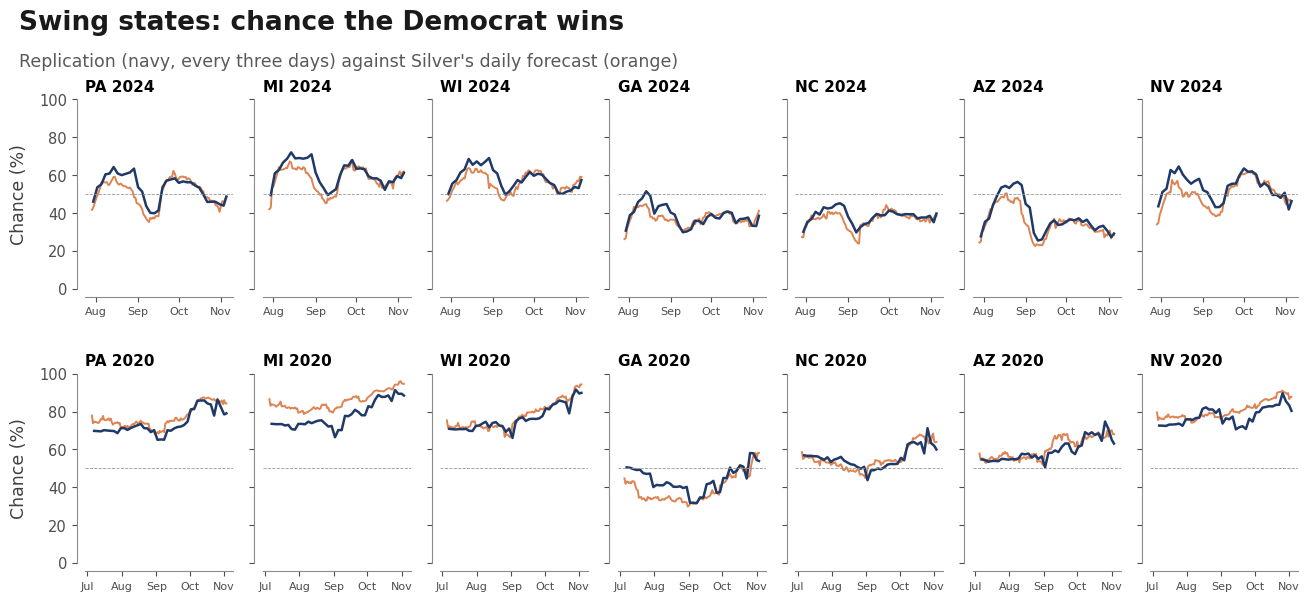

In [5]:
fig, axes = figure("Swing states: chance the Democrat wins",
                   "Replication (navy, every three days) against Silver's daily forecast (orange)", nrows=2, ncols=7,
                   height=6.5, sharey=True)
for row, c in enumerate(CY):
    for col, s in enumerate(SWING):
        ax = axes[row, col]
        o = tss[c][tss[c].geo == s]
        x = silver_window(c, silver[c][1][silver[c][1].geo == s])
        ax.plot(x.date, 100 * x.win_D, color=SILVER, lw=1.4)
        ax.plot(o.date, 100 * o.win_D, color=REPLICATION, lw=1.8)
        ax.axhline(50, color=GREY, lw=0.6, ls="--"); ax.set_ylim(0, 100)
        ax.set_title(f"{s} {c}", fontsize=11); dates(ax, "%b"); ax.tick_params(axis="x", labelsize=8)
    axes[row, 0].set_ylabel("Chance (%)")
plt.show()

## 2. Polling averages

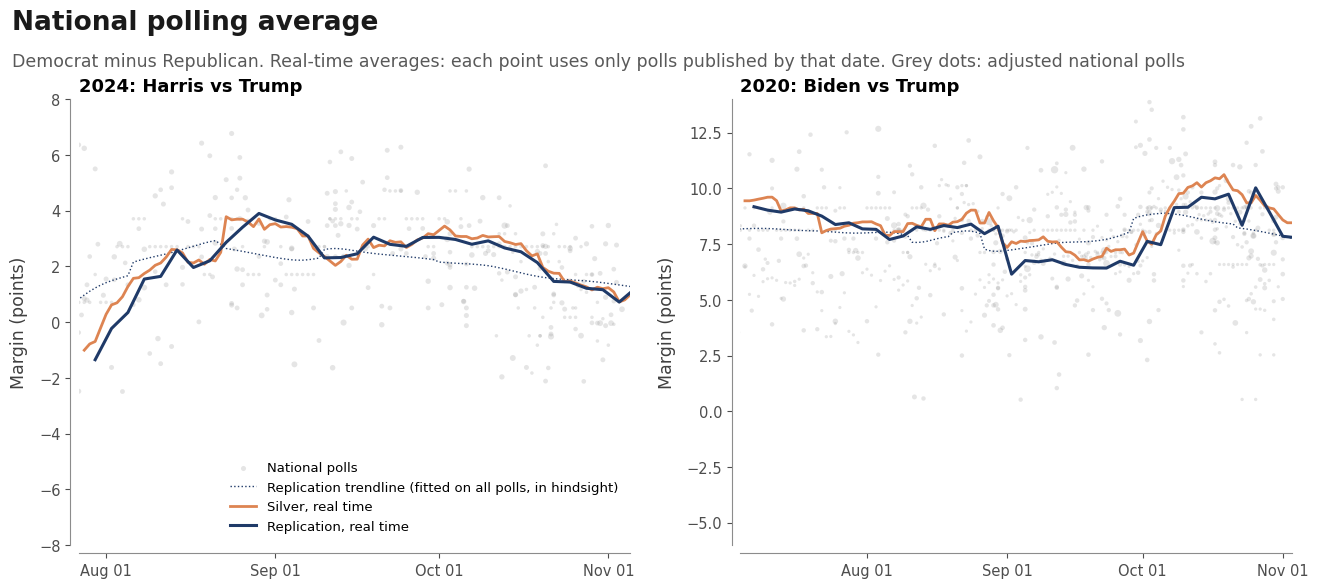

In [6]:
def silver_nat_avg(c):
    a = D.cached_excel("2024-11-05_poll-average") if c == 2024 else \
        pd.read_csv(C.ARCHIVE / "2020-general-data" / "presidential_poll_averages_2020.csv")
    a = a[a.state == "National"].copy(); a["date"] = pd.to_datetime(a.modeldate, format="mixed")
    w = a.pivot_table(index="date", columns="candidate_name", values="pct_estimate")
    return (w[C.CYCLES[c]["dem"]] - w[C.CYCLES[c]["rep"]]).rename("margin").reset_index()

fig, axes = figure("National polling average",
                   "Democrat minus Republican. Real-time averages: each point uses only polls published by that date. "
                   "Grey dots: adjusted national polls", ncols=2, height=6.3)
for ax, c in zip(axes, CY):
    d = OUT / str(c) / C.ELECTION_DAYS[c]
    p = pd.read_csv(d / "polls.csv", parse_dates=["mid"]); tr = pd.read_csv(d / "national_trend.csv", parse_dates=["date"])
    n = p[p.geo == "US"]
    s = silver_window(c, silver_nat_avg(c))
    ax.scatter(n.mid, n.adj_D - n.adj_R, s=5 + 8 * n.weight, color=GREY, alpha=0.25, lw=0, label="National polls")
    ax.plot(tr.date, tr.D - tr.R, color=REPLICATION, lw=1, ls=":", label="Replication trendline (fitted on all polls, in hindsight)")
    ax.plot(s.date, s.margin, color=SILVER, lw=2, label="Silver, real time")
    ax.plot(ts[c].date, ts[c].national_margin_polls_raw, color=REPLICATION, lw=2.2, label="Replication, real time")
    ax.set_xlim(ts[c].date.min() - pd.Timedelta(days=3), ts[c].date.max())
    ax.set_ylim(-6, 14) if c == 2020 else ax.set_ylim(-8, 8)
    ax.set_title(NAME[c]); ax.set_ylabel("Margin (points)"); dates(ax)
axes[0].legend(loc="lower right", fontsize=9.5)
plt.show()

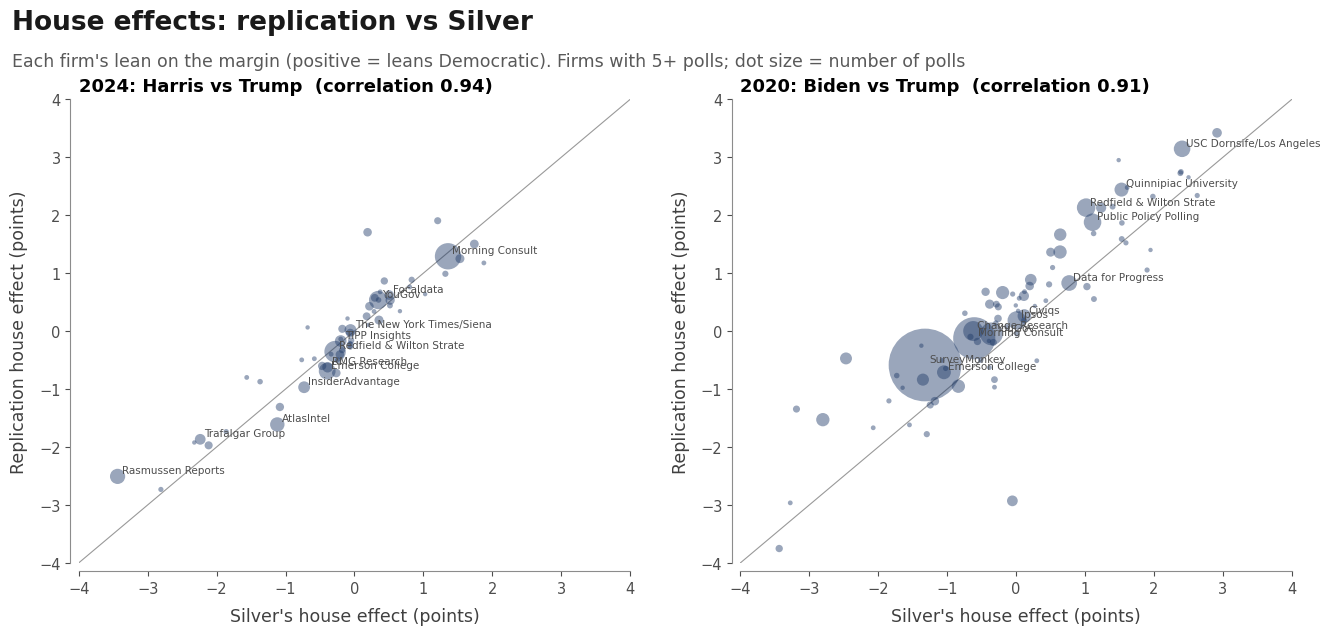

In [7]:
def silver_house(c):
    kind, ref = C.CYCLES[c]["pollist"]
    pl = D.cached_excel(ref) if kind == "hosted" else pd.read_csv(C.ARCHIVE / ref)
    pl = pl[pl.candidate_name.isin([C.CYCLES[c]["dem"], C.CYCLES[c]["rep"]])].copy()
    pl["he"] = pl.pct - pl.house_adjusted_pct
    w = pl.pivot_table(index="pollster", columns="candidate_name", values="he", aggfunc="mean")
    return w[C.CYCLES[c]["dem"]] - w[C.CYCLES[c]["rep"]]

fig, axes = figure("House effects: replication vs Silver",
                   "Each firm's lean on the margin (positive = leans Democratic). Firms with 5+ polls; dot size = number of polls",
                   ncols=2, height=6.5)
for ax, c in zip(axes, CY):
    h = pd.read_csv(OUT / str(c) / C.ELECTION_DAYS[c] / "house_effects.csv", index_col=0)
    h["silver"] = silver_house(c); h = h[h.polls >= 5].dropna(subset=["silver"])
    ax.scatter(h.silver, h.margin, s=h.polls * 2, color=REPLICATION, alpha=0.45, lw=0)
    for n, r in h.sort_values("polls", ascending=False).head(12).iterrows():
        ax.annotate(n[:24], (r.silver, r.margin), fontsize=7.5, color="0.3", xytext=(3, 2), textcoords="offset points")
    identity(ax, [-4, 4])
    ax.set_title(f"{NAME[c]}  (correlation {np.corrcoef(h.silver, h.margin)[0, 1]:.2f})")
    ax.set_xlabel("Silver's house effect (points)"); ax.set_ylabel("Replication house effect (points)")
plt.show()

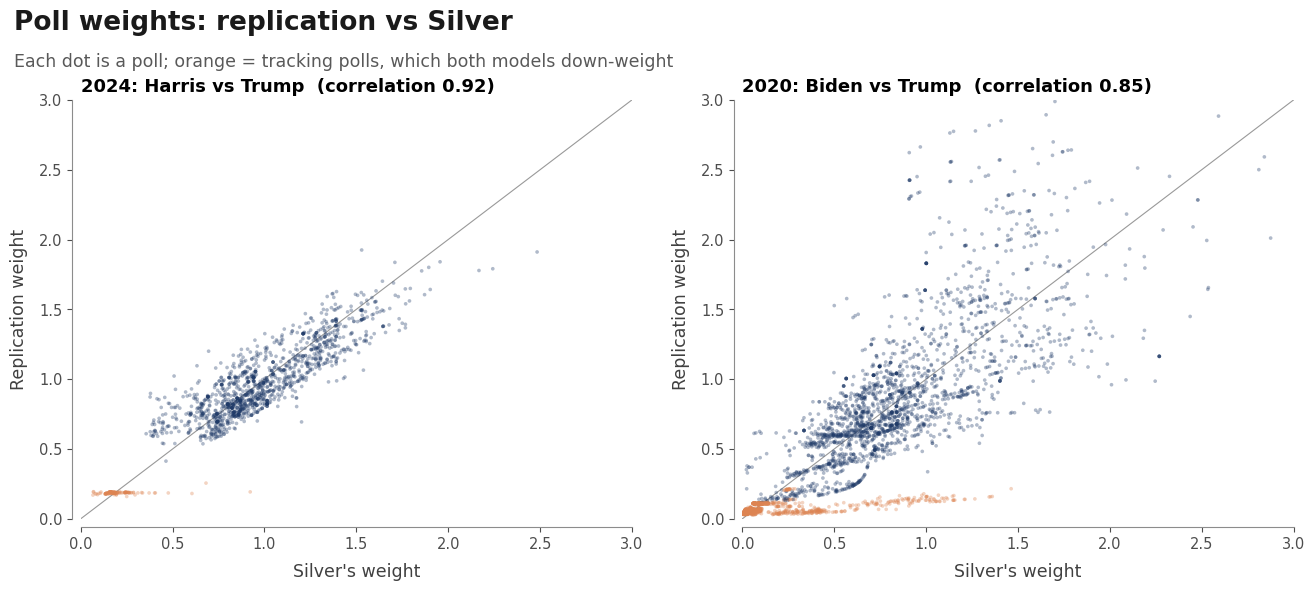

In [10]:
fig, axes = figure("Poll weights: replication vs Silver",
                   "Each dot is a poll; orange = tracking polls, which both models down-weight", ncols=2)
for ax, c in zip(axes, CY):
    p = pd.read_csv(OUT / str(c) / C.ELECTION_DAYS[c] / "polls.csv")
    ok = p.silver_weight > 0
    ax.scatter(p.silver_weight[ok], p.weight[ok], s=7, alpha=0.35, lw=0, c=np.where(p.tracking[ok], SILVER, REPLICATION))
    identity(ax, [0, 3])
    ax.set_title(f"{NAME[c]}  (correlation {np.corrcoef(p.silver_weight[ok], p.weight[ok])[0, 1]:.2f})")
    ax.set_xlabel("Silver's weight"); ax.set_ylabel("Replication weight")
plt.show()

## 3. Election Day by state

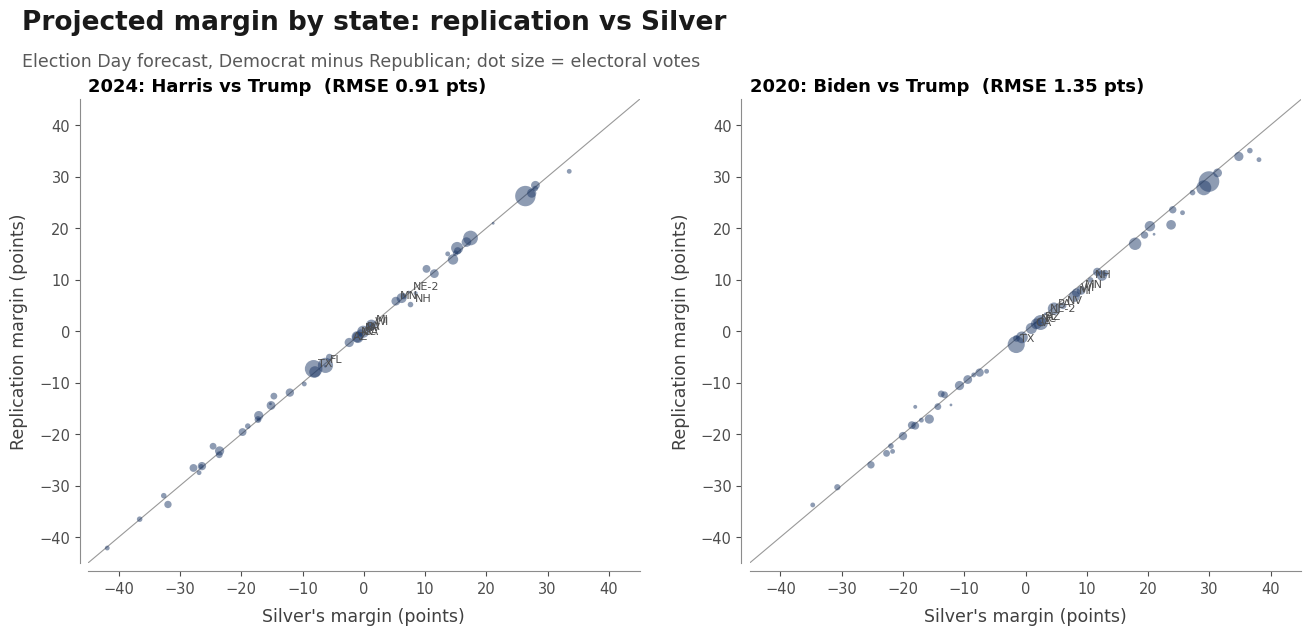

In [11]:
fig, axes = figure("Projected margin by state: replication vs Silver",
                   "Election Day forecast, Democrat minus Republican; dot size = electoral votes", ncols=2, height=6.5)
for ax, c in zip(axes, CY):
    e = eday[c]
    ax.scatter(e.silver_margin, e.margin, s=e.ev * 4, color=REPLICATION, alpha=0.5, lw=0)
    for g in SWING + ["FL", "TX", "NH", "MN", "NE-2"]:
        ax.annotate(g, (e.loc[g, "silver_margin"], e.loc[g, "margin"]), fontsize=8, color="0.3", xytext=(3, 2), textcoords="offset points")
    identity(ax, [-45, 45])
    ax.set_title(f"{NAME[c]}  (RMSE {np.sqrt(((e.margin - e.silver_margin) ** 2).mean()):.2f} pts)")
    ax.set_xlabel("Silver's margin (points)"); ax.set_ylabel("Replication margin (points)")
plt.show()

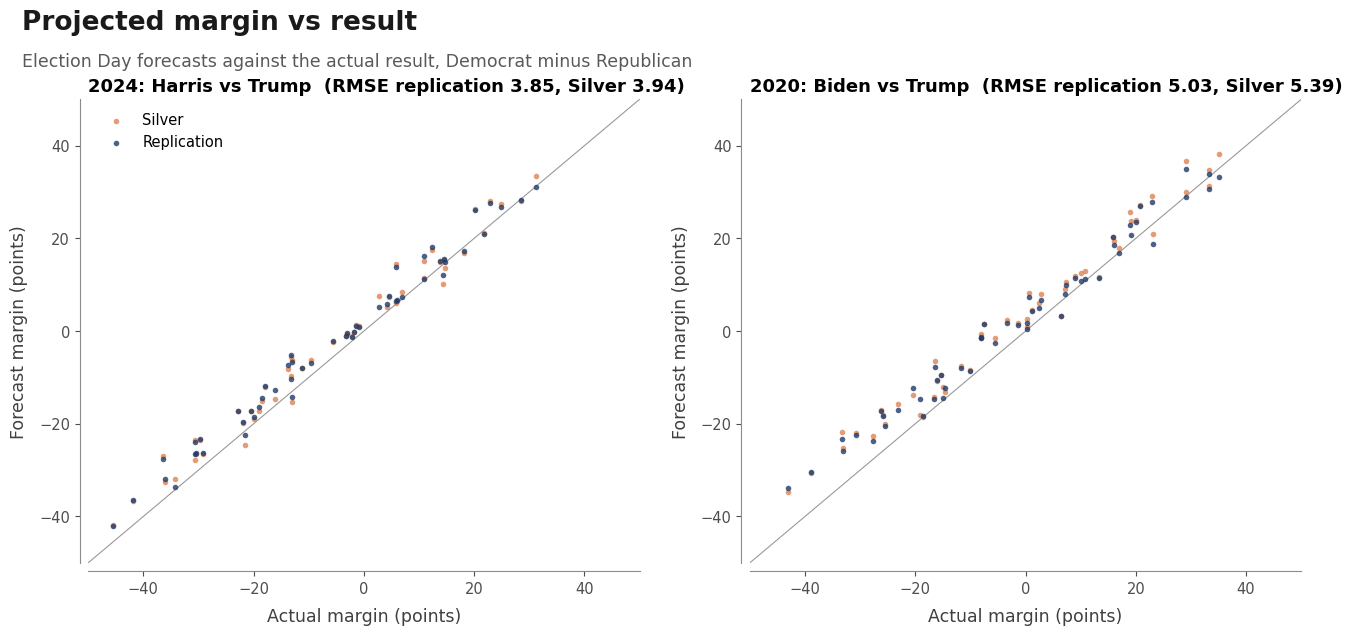

In [12]:
fig, axes = figure("Projected margin vs result",
                   "Election Day forecasts against the actual result, Democrat minus Republican", ncols=2, height=6.5)
for ax, c in zip(axes, CY):
    e = eday[c].dropna(subset=["actual_margin"])
    ax.scatter(e.actual_margin, e.silver_margin, s=16, color=SILVER, alpha=0.8, lw=0, label="Silver")
    ax.scatter(e.actual_margin, e.margin, s=16, color=REPLICATION, alpha=0.8, lw=0, label="Replication")
    identity(ax, [-50, 50])
    r_o = np.sqrt(((e.margin - e.actual_margin) ** 2).mean()); r_s = np.sqrt(((e.silver_margin - e.actual_margin) ** 2).mean())
    ax.set_title(f"{NAME[c]}  (RMSE replication {r_o:.2f}, Silver {r_s:.2f})")
    ax.set_xlabel("Actual margin (points)"); ax.set_ylabel("Forecast margin (points)")
axes[0].legend(loc="upper left")
plt.show()

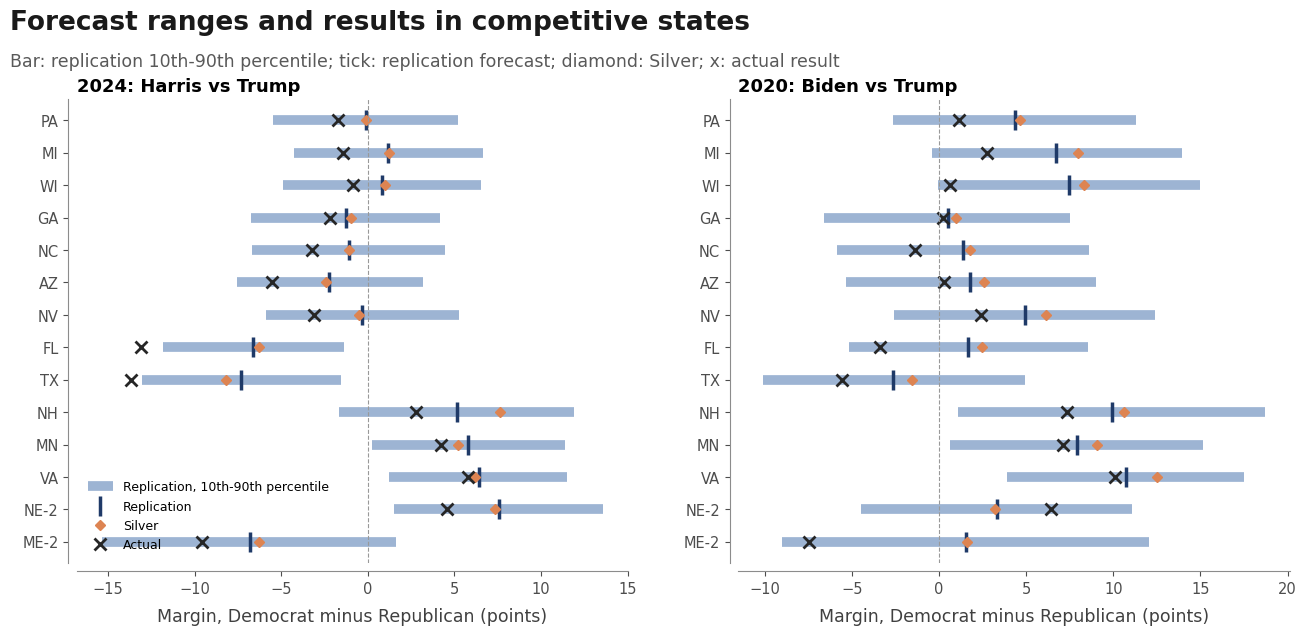

In [13]:
keys = SWING + ["FL", "TX", "NH", "MN", "VA", "NE-2", "ME-2"]
fig, axes = figure("Forecast ranges and results in competitive states",
                   "Bar: replication 10th-90th percentile; tick: replication forecast; diamond: Silver; x: actual result", ncols=2, height=6.5)
for ax, c in zip(axes, CY):
    e = eday[c].loc[keys]; y = np.arange(len(keys))
    ax.hlines(y, e.margin_p10, e.margin_p90, color=LIGHT, lw=7, label="Replication, 10th-90th percentile")
    ax.plot(e.margin, y, "|", color=REPLICATION, ms=14, mew=2.5, label="Replication")
    ax.plot(e.silver_margin, y, "D", color=SILVER, ms=5, label="Silver")
    ax.plot(e.actual_margin, y, "x", color=ACTUAL, ms=8, mew=2, label="Actual")
    ax.axvline(0, color=GREY, lw=0.8, ls="--")
    ax.set_yticks(y, keys); ax.invert_yaxis(); ax.set_title(NAME[c]); ax.set_xlabel("Margin, Democrat minus Republican (points)")
axes[0].legend(loc="lower left", fontsize=9)
plt.show()

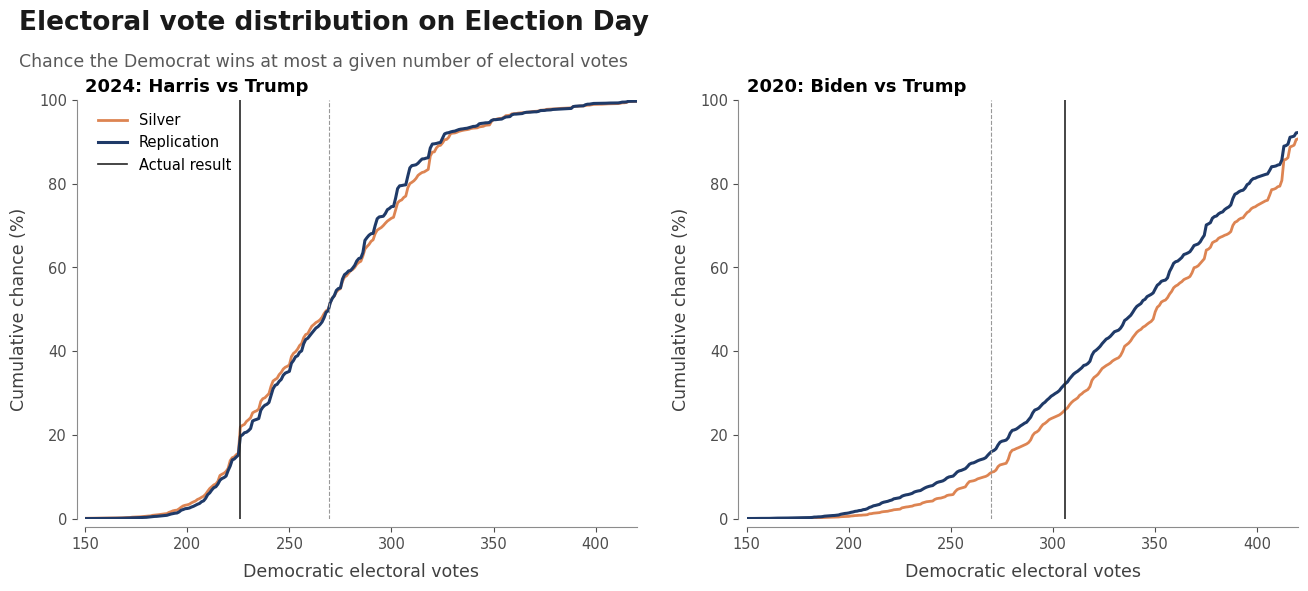

In [14]:
def silver_ev(c):
    if c == 2024:
        e = D.cached_excel("2024-11-05_ev-probabilities"); col = "evprob_inc"
    else:
        e = pd.read_csv(C.ARCHIVE / "2020-general-data" / "presidential_ev_probabilities_2020.csv"); col = "evprob_chal"
    e["date"] = pd.to_datetime(e.modeldate, format="mixed")
    e = e[e.date == e.date.max()]
    s = e.groupby("total_ev")[col].mean().sort_index()
    return s.reindex(range(539), fill_value=0)

fig, axes = figure("Electoral vote distribution on Election Day",
                   "Chance the Democrat wins at most a given number of electoral votes", ncols=2)
for ax, c in zip(axes, CY):
    o = pd.read_csv(OUT / str(c) / C.ELECTION_DAYS[c] / "ev_distribution.csv", index_col=0).prob
    s = silver_ev(c)
    ax.plot(s.index, 100 * s.cumsum() / s.sum(), color=SILVER, lw=2, label="Silver")
    ax.plot(o.index, 100 * o.cumsum(), color=REPLICATION, lw=2.2, label="Replication")
    ax.axvline(269.5, color=GREY, lw=0.8, ls="--")
    ax.axvline(summ[c]["actual"]["ev_D"], color=ACTUAL, lw=1.2, label="Actual result")
    ax.set_xlim(150, 420); ax.set_ylim(0, 100); ax.set_title(NAME[c])
    ax.set_xlabel("Democratic electoral votes"); ax.set_ylabel("Cumulative chance (%)")
axes[0].legend(loc="upper left")
plt.show()

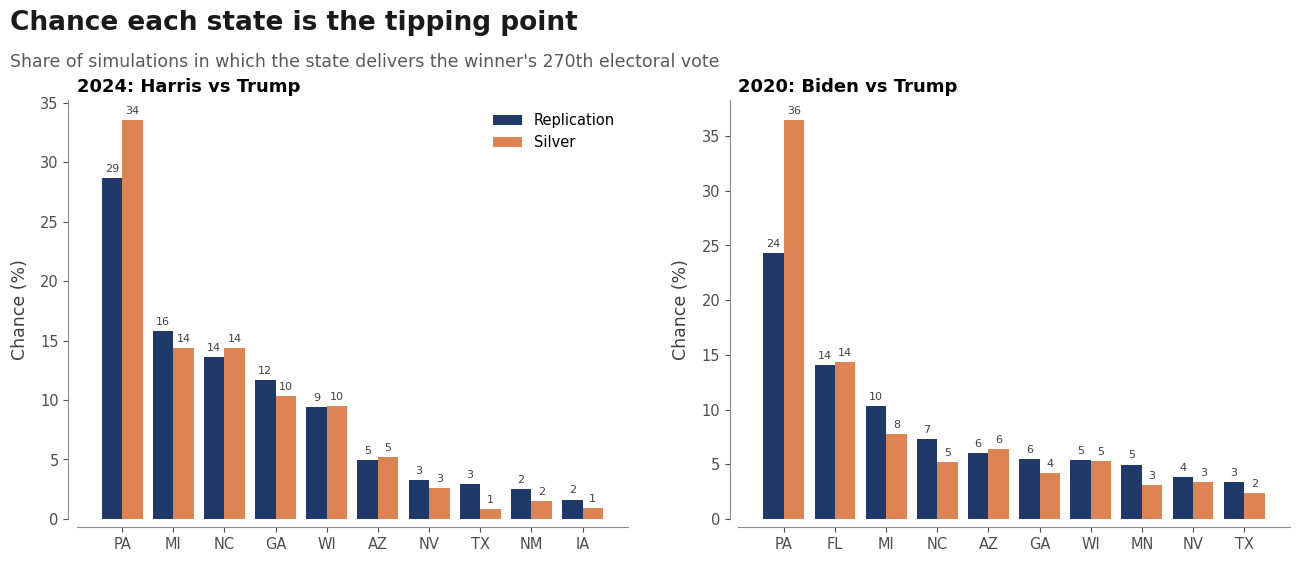

In [15]:
fig, axes = figure("Chance each state is the tipping point",
                   "Share of simulations in which the state delivers the winner's 270th electoral vote", ncols=2)
for ax, c in zip(axes, CY):
    e = eday[c].sort_values("tipping", ascending=False).head(10); x = np.arange(len(e))
    b1 = ax.bar(x - 0.2, 100 * e.tipping, 0.4, color=REPLICATION, label="Replication")
    b2 = ax.bar(x + 0.2, 100 * e.silver_tipping, 0.4, color=SILVER, label="Silver")
    bar_labels(ax, b1, 100 * e.tipping, "{:.0f}", 8); bar_labels(ax, b2, 100 * e.silver_tipping, "{:.0f}", 8)
    ax.set_xticks(x, e.index); ax.set_title(NAME[c]); ax.set_ylabel("Chance (%)")
axes[0].legend(loc="upper right")
plt.show()

## 4. Calibration across contests

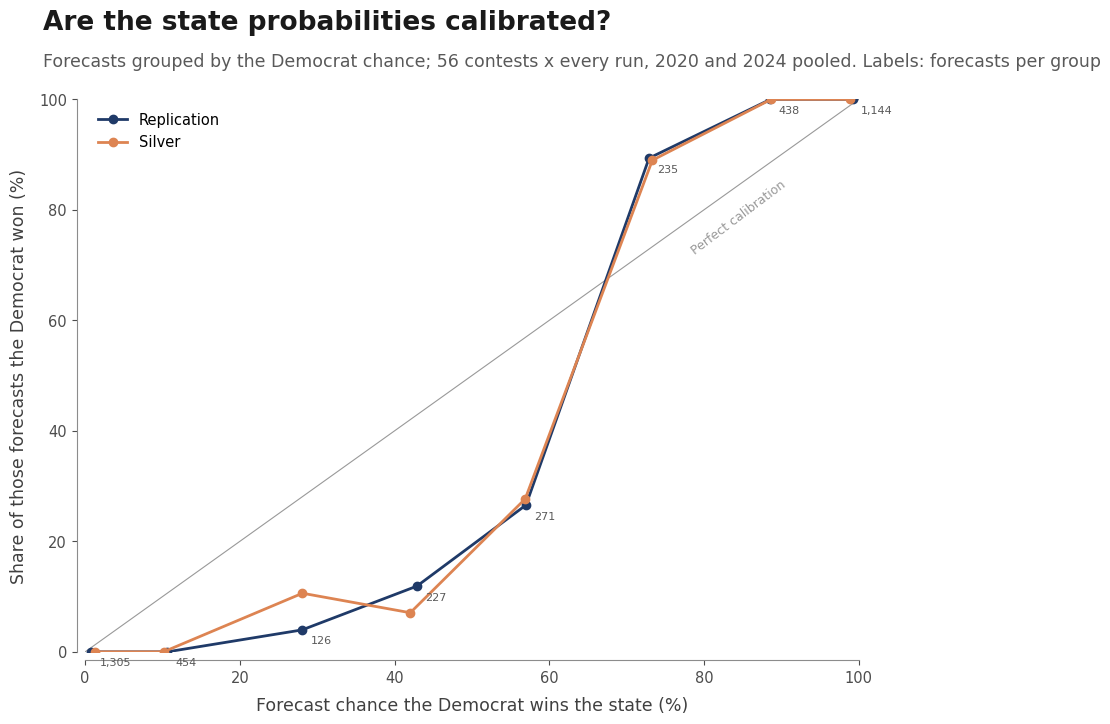

In [17]:
rows = []
for c in CY:
    x = tss[c].dropna(subset=["actual_margin"]).copy()
    x["won"] = (x.actual_margin > 0).astype(int); x["cycle"] = c
    rows.append(x)
allx = pd.concat(rows)
bins = [0, .05, .2, .35, .5, .65, .8, .95, 1.0001]
fig, ax = figure("Are the state probabilities calibrated?",
                 "Forecasts grouped by the Democrat chance; 56 contests x every run, 2020 and 2024 pooled. "
                 "Labels: forecasts per group", width=8.5, height=7.5)
for col, lab, color in [("win_D", "Replication", REPLICATION), ("silver_win_D", "Silver", SILVER)]:
    x = allx.dropna(subset=[col])
    b = x.groupby(pd.cut(x[col], bins, include_lowest=True), observed=True)
    ax.plot(100 * b[col].mean(), 100 * b.won.mean(), "o-", color=color, lw=2, label=lab)
    if lab == "Replication":
        for xm, ym, n in zip(b[col].mean(), b.won.mean(), b.size()):
            ax.annotate(f"{n:,}", (100 * xm, 100 * ym), fontsize=8, color="0.35", xytext=(6, -10), textcoords="offset points")
identity(ax, [0, 100])
ax.annotate("Perfect calibration", (78, 72), rotation=37, fontsize=9, color=GREY)
ax.set_xlabel("Forecast chance the Democrat wins the state (%)"); ax.set_ylabel("Share of those forecasts the Democrat won (%)")
ax.legend(loc="upper left")
plt.show()

In [18]:
def scores(x, p):
    x = x.dropna(subset=[p]); q = x[p].clip(1e-4, 1 - 1e-4)
    return {"Brier": ((q - x.won) ** 2).mean(), "log loss": -(x.won * np.log(q) + (1 - x.won) * np.log(1 - q)).mean()}
tab = []
for c in CY:
    xc = allx[allx.cycle == c]
    for when, x in [("Election Day", xc[xc.date == xc.date.max()]), ("all runs", xc)]:
        e = x.dropna(subset=["silver_margin"])
        so, ss = scores(x, "win_D"), scores(x, "silver_win_D")
        tab.append({"cycle": c, "runs": when, "Brier replication": so["Brier"], "Brier Silver": ss["Brier"],
                    "log loss replication": so["log loss"], "log loss Silver": ss["log loss"],
                    "margin RMSE replication": np.sqrt(((e.margin - e.actual_margin) ** 2).mean()),
                    "margin RMSE Silver": np.sqrt(((e.silver_margin - e.actual_margin) ** 2).mean())})
pd.DataFrame(tab).set_index(["cycle", "runs"]).round(3)

Brier replication  Brier Silver  log loss replication  \
cycle runs                                                                  
2024  Election Day              0.030         0.032                 0.100   
      all runs                  0.035         0.034                 0.115   
2020  Election Day              0.038         0.040                 0.128   
      all runs                  0.047         0.045                 0.169   

                    log loss Silver  margin RMSE replication  \
cycle runs                                                     
2024  Election Day            0.112                    3.847   
      all runs                0.125                    3.914   
2020  Election Day            0.137                    5.032   
      all runs                0.165                    4.651   

                    margin RMSE Silver  
cycle runs                              
2024  Election Day               3.940  
      all runs                   3.809  
2020  Election Day               5.393  
      all runs                   4.612

## 5. Economic index

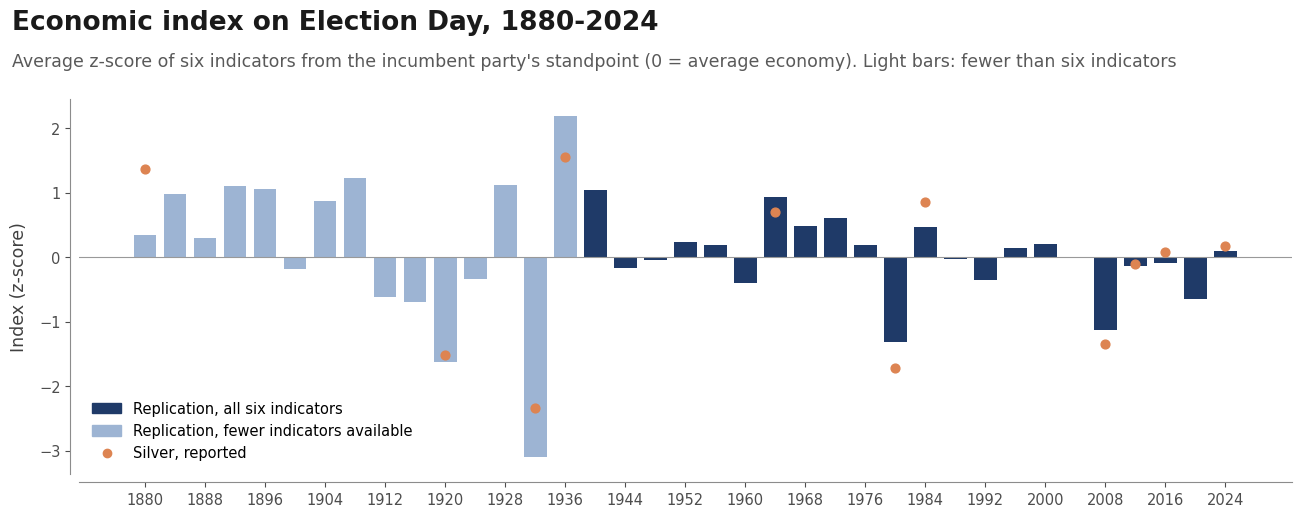

In [19]:
ed = E.election_day_index()
fig, ax = figure("Economic index on Election Day, 1880-2024",
                 "Average z-score of six indicators from the incumbent party's standpoint (0 = average economy). "
                 "Light bars: fewer than six indicators", height=5.5)
colors = [LIGHT if n < 6 else REPLICATION for n in ed.n_indicators]
ax.bar(ed.index, ed["index"], width=3, color=colors)
rep = pd.Series(E.REPORTED)
ax.scatter(rep.index, rep.values, color=SILVER, zorder=3, s=40)
ax.axhline(0, color=GREY, lw=0.8)
from matplotlib.patches import Patch
from matplotlib.lines import Line2D
ax.legend([Patch(color=REPLICATION), Patch(color=LIGHT), Line2D([], [], marker="o", ls="", color=SILVER)],
          ["Replication, all six indicators", "Replication, fewer indicators available", "Silver, reported"], loc="lower left")
ax.set_xticks(ed.index[::2]); ax.set_ylabel("Index (z-score)")
plt.show()

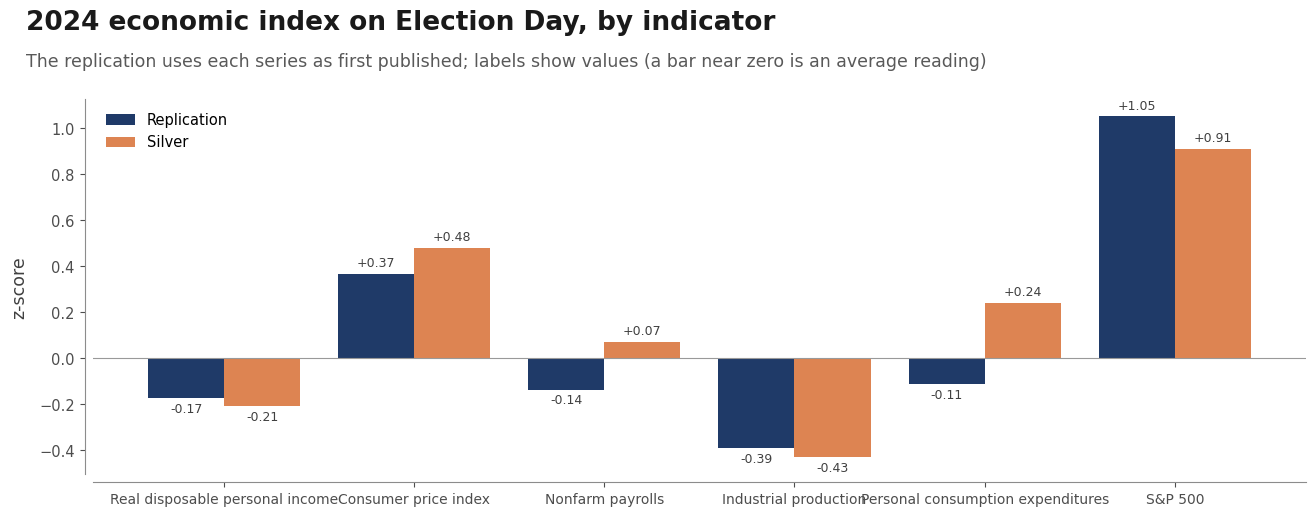

In [21]:
x = np.arange(6); repl24 = ed.loc[2024, E.INDICATORS].astype(float); sb24 = pd.Series(E.REPORTED_2024)[E.INDICATORS]
fig, ax = figure("2024 economic index on Election Day, by indicator",
                 "The replication uses each series as first published; labels show values (a bar near zero is an average reading)", height=5.5)
b1 = ax.bar(x - 0.2, repl24, 0.4, color=REPLICATION, label="Replication"); b2 = ax.bar(x + 0.2, sb24, 0.4, color=SILVER, label="Silver")
bar_labels(ax, b1, repl24); bar_labels(ax, b2, sb24)
ax.set_xticks(x, [E.LABELS[k] for k in E.INDICATORS], fontsize=10); ax.axhline(0, color=GREY, lw=0.8)
ax.set_ylabel("z-score"); ax.legend(loc="upper left")
plt.show()

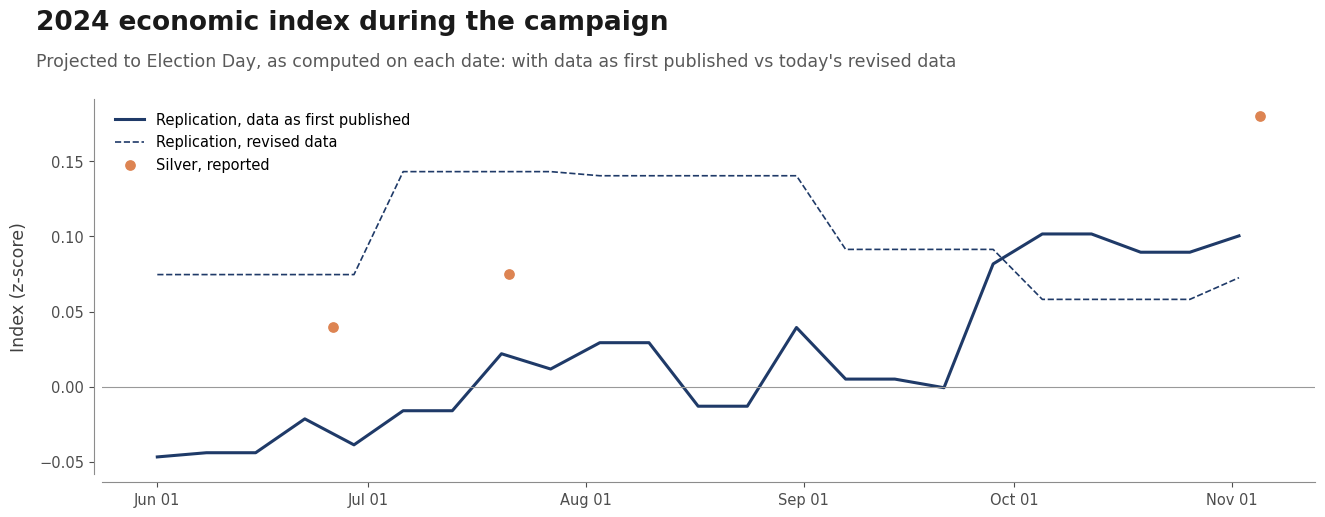

In [23]:
wk = pd.date_range("2024-06-01", "2024-11-05", freq="7D")
rev = pd.DataFrame([{"date": d, "rev": E.index_asof(d, 2024, pit=False)["index_projected"],
                     "pit": E.index_asof(d, 2024)["index_projected"]} for d in wk])
sb_jul21 = np.mean([-0.65, 0.45, 0.22, 0.02, -0.23, 0.64])
fig, ax = figure("2024 economic index during the campaign",
                 "Projected to Election Day, as computed on each date: with data as first published vs today's revised data",
                 height=5.5)
ax.plot(rev.date, rev.pit, color=REPLICATION, lw=2.2, label="Replication, data as first published")
ax.plot(rev.date, rev.rev, color=REPLICATION, lw=1.2, ls="--", label="Replication, revised data")
ax.scatter([pd.Timestamp("2024-06-26"), pd.Timestamp("2024-07-21"), pd.Timestamp("2024-11-05")], [0.04, sb_jul21, 0.18],
           color=SILVER, s=45, zorder=3, label="Silver, reported")
ax.axhline(0, color=GREY, lw=0.8); ax.set_ylabel("Index (z-score)"); dates(ax); ax.legend(loc="upper left")
plt.show()

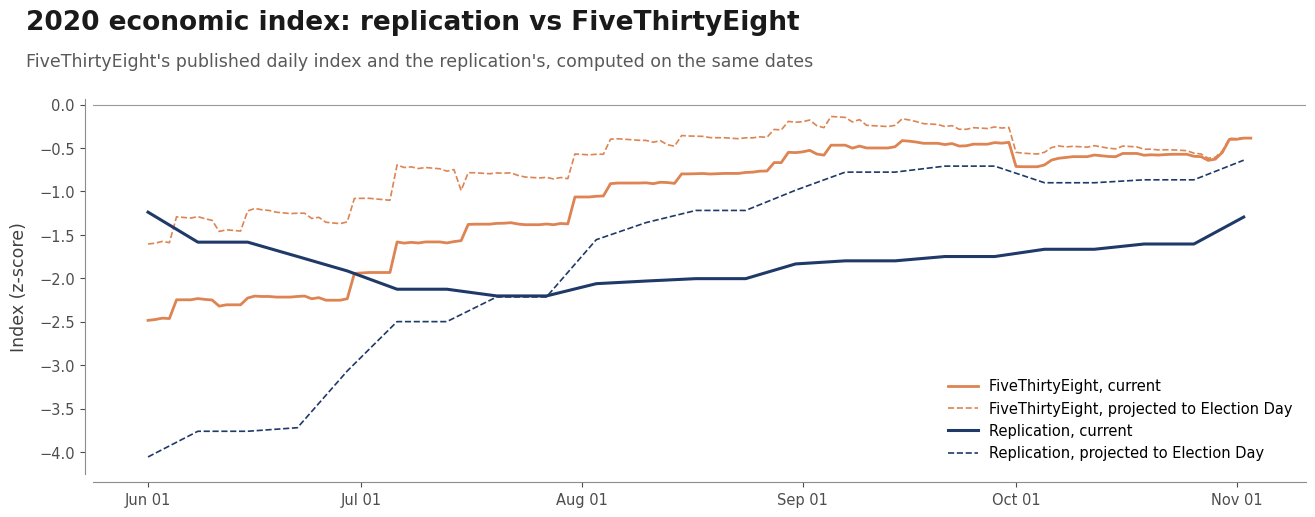

In [24]:
e20 = E.silver_2020_daily()
s20 = e20.groupby("date")[["current_zscore", "projected_zscore"]].mean()
o = pd.DataFrame([{"date": d, **{k: v for k, v in E.index_asof(d, 2020).items() if k.startswith("index")}}
                  for d in s20.index[::7]]).set_index("date")
fig, ax = figure("2020 economic index: replication vs FiveThirtyEight",
                 "FiveThirtyEight's published daily index and the replication's, computed on the same dates", height=5.5)
ax.plot(s20.index, s20.current_zscore, color=SILVER, lw=2, label="FiveThirtyEight, current")
ax.plot(s20.index, s20.projected_zscore, color=SILVER, lw=1.2, ls="--", label="FiveThirtyEight, projected to Election Day")
ax.plot(o.index, o.index_current, color=REPLICATION, lw=2.2, label="Replication, current")
ax.plot(o.index, o.index_projected, color=REPLICATION, lw=1.2, ls="--", label="Replication, projected to Election Day")
ax.axhline(0, color=GREY, lw=0.8); ax.set_ylabel("Index (z-score)"); dates(ax); ax.legend(loc="lower right")
plt.show()

## 6. Fundamentals

In [25]:
fm = F.fit(2020)
fm0 = F.fit(2020, target_weight=0)
print(f"With Silver's reported values: damping {fm['gamma']}, half-life {fm['half_life']}y, "
      f"left-out RMSE since 1948 {fm['loo_rmse_post1948']:.2f} pts")
print(f"History only:                  damping {fm0['gamma']}, half-life {fm0['half_life']}y, "
      f"left-out RMSE since 1948 {fm0['loo_rmse_post1948']:.2f} pts")

With Silver's reported values: damping 4, half-life 24y, left-out RMSE since 1948 8.07 pts
History only:                  damping 6, half-life 24y, left-out RMSE since 1948 8.17 pts


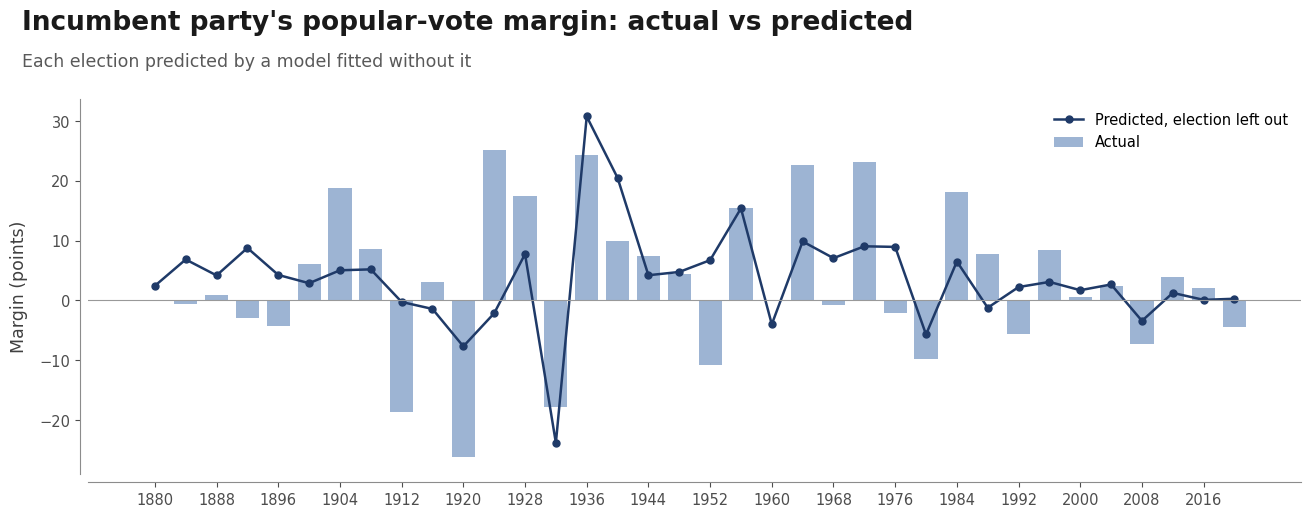

In [27]:
fig, ax = figure("Incumbent party's popular-vote margin: actual vs predicted",
                 "Each election predicted by a model fitted without it", height=5.5)
ax.bar(fm["actual"].index, fm["actual"], width=3, color=LIGHT, label="Actual")
ax.plot(fm["loo"].index, fm["loo"], "o-", color=REPLICATION, lw=1.8, ms=5, label="Predicted, election left out")
ax.axhline(0, color=GREY, lw=0.8); ax.set_xticks(fm["actual"].index[::2]); ax.set_ylabel("Margin (points)")
ax.legend(loc="upper right")
plt.show()

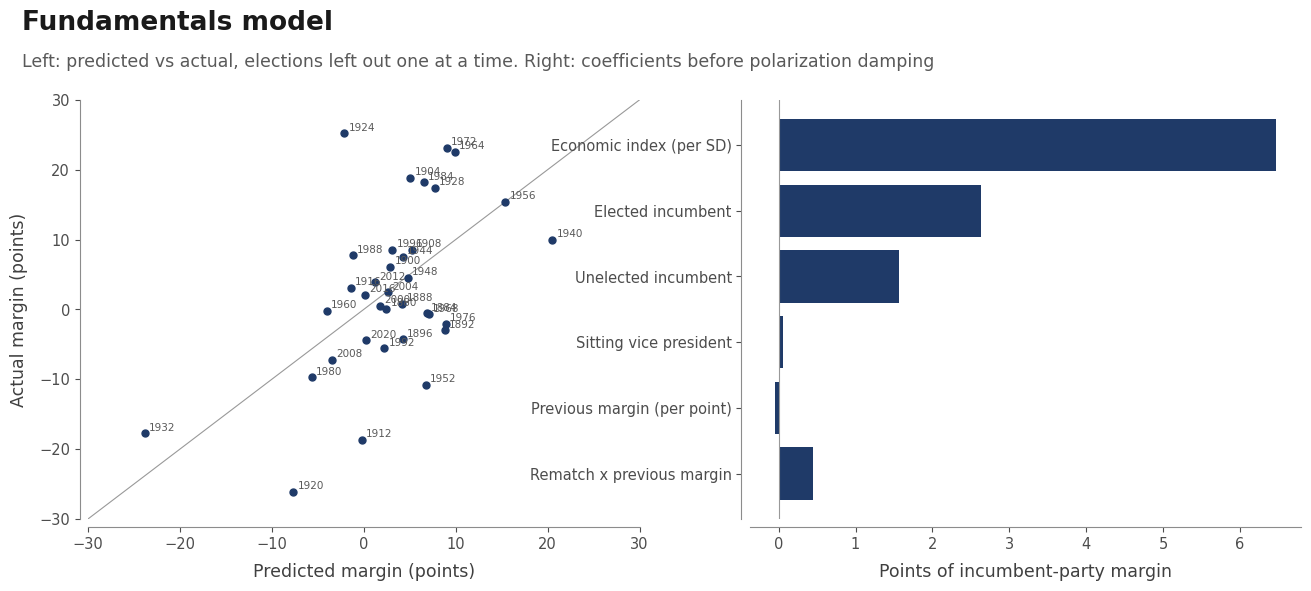

In [28]:
fig, axes = figure("Fundamentals model", "Left: predicted vs actual, elections left out one at a time. "
                   "Right: coefficients before polarization damping", ncols=2)
ax = axes[0]
ax.scatter(fm["loo"], fm["actual"], color=REPLICATION, s=25)
for y in fm["actual"].index:
    ax.annotate(str(y), (fm["loo"][y], fm["actual"][y]), fontsize=7.5, color="0.35", xytext=(3, 2), textcoords="offset points")
identity(ax, [-30, 30]); ax.set_xlabel("Predicted margin (points)"); ax.set_ylabel("Actual margin (points)")
ax = axes[1]
labels = {"economy": "Economic index (per SD)", "elected": "Elected incumbent", "unelected": "Unelected incumbent",
          "vp": "Sitting vice president", "prev_margin": "Previous margin (per point)", "rematch_x_prev": "Rematch x previous margin"}
b = fm["beta"].drop("const").rename(labels)
bars = ax.barh(b.index, b.values, color=REPLICATION); ax.axvline(0, color=GREY, lw=0.8); ax.invert_yaxis()
ax.set_xlabel("Points of incumbent-party margin")
plt.show()

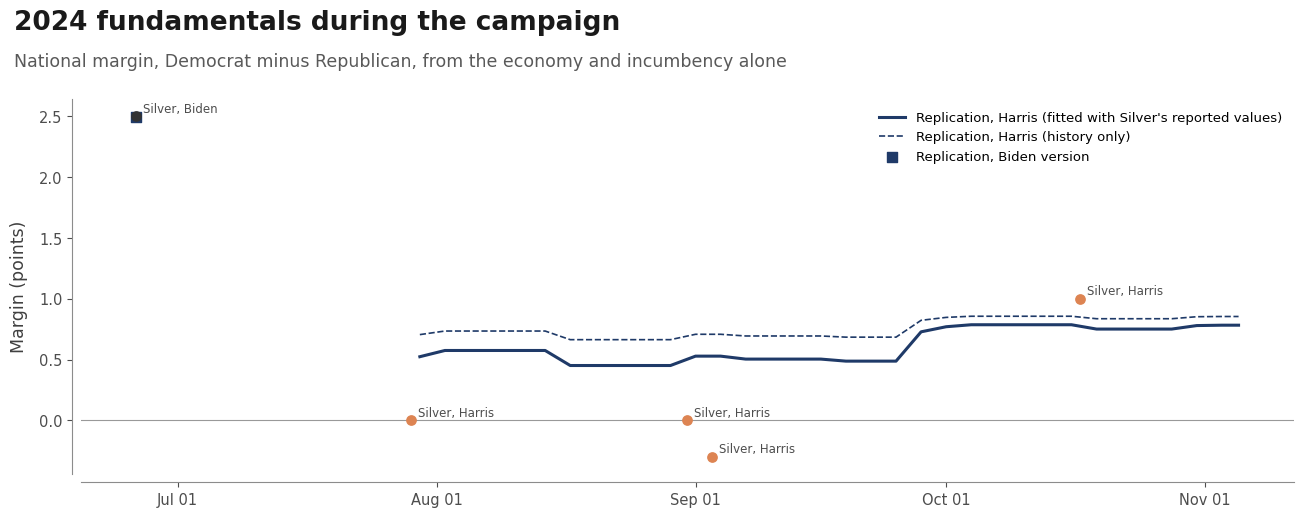

In [29]:
from model.president.history import elections
p24 = elections(2024, 2024).loc[2024, "polarization"]
t = ts[2024]
hist_only = [F.predict(2024, e, "vp", 4.45, 0, p24, m=fm0) for e in t.economic_index]
fig, ax = figure("2024 fundamentals during the campaign",
                 "National margin, Democrat minus Republican, from the economy and incumbency alone", height=5.5)
ax.plot(t.date, t.fundamentals_margin, color=REPLICATION, lw=2.2, label="Replication, Harris (fitted with Silver's reported values)")
ax.plot(t.date, hist_only, color=REPLICATION, lw=1.2, ls="--", label="Replication, Harris (history only)")
for k, v in C.FUNDAMENTALS_REPORTED.items():
    d, who = k.split()
    ax.scatter(pd.Timestamp(d), v, color=SILVER if who == "Harris" else "0.2", s=45, zorder=3)
    ax.annotate(f"Silver, {who}", (pd.Timestamp(d), v), fontsize=8.5, color="0.3", xytext=(5, 3), textcoords="offset points")
ax.scatter(pd.Timestamp("2024-06-26"), F.national_margin(2024, "2024-06-26", tier="elected", rematch=1)[0],
           marker="s", color=REPLICATION, s=45, label="Replication, Biden version")
ax.axhline(0, color=GREY, lw=0.8); ax.set_ylabel("Margin (points)"); dates(ax); ax.legend(loc="upper right", fontsize=9.5)
plt.show()

## 7. Uncertainty index

In [30]:
ucal, uh, ud, ufinal = U.calibrate(save=False)
print(f"drift SD = {ucal['drift_const']:.2f} x days^(1/3) x exp({ucal['index_kappa']:.2f} x index); "
      f"Election Day polling error 1968-2024: RMSE {ucal['ed_error_rmse_1968_2024']:.2f} pts")

drift SD = 1.13 x days^(1/3) x exp(1.03 x index); Election Day polling error 1968-2024: RMSE 3.73 pts


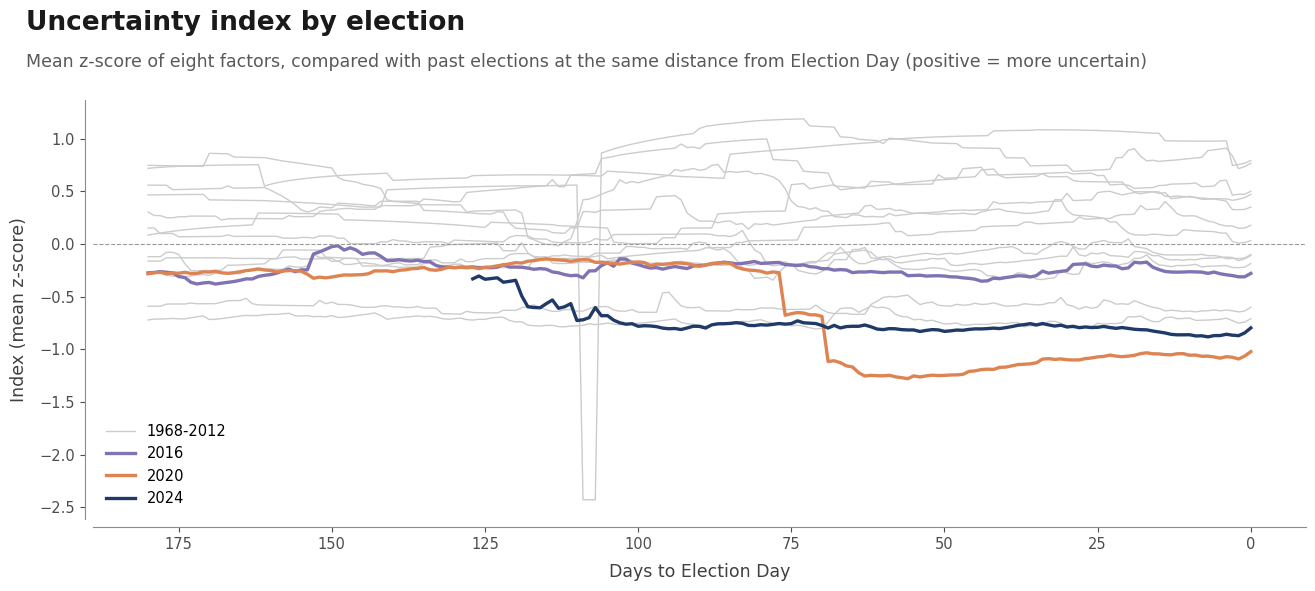

In [31]:
fig, ax = figure("Uncertainty index by election",
                 "Mean z-score of eight factors, compared with past elections at the same distance from Election Day "
                 "(positive = more uncertain)", height=6)
hi = {2016: "#8172B3", 2020: SILVER, 2024: REPLICATION}
for c in sorted(uh.cycle.unique()):
    x = uh[(uh.cycle == c) & (uh.days_left <= 180)].sort_values("days_left")
    if c in hi:
        ax.plot(x.days_left, x["index"], color=hi[c], lw=2.4, label=str(c))
    else:
        ax.plot(x.days_left, x["index"], color="0.8", lw=1, label="1968-2012" if c == 1968 else None)
ax.invert_xaxis(); ax.axhline(0, color=GREY, lw=0.8, ls="--"); ax.legend(loc="lower left")
ax.set_xlabel("Days to Election Day"); ax.set_ylabel("Index (mean z-score)")
plt.show()

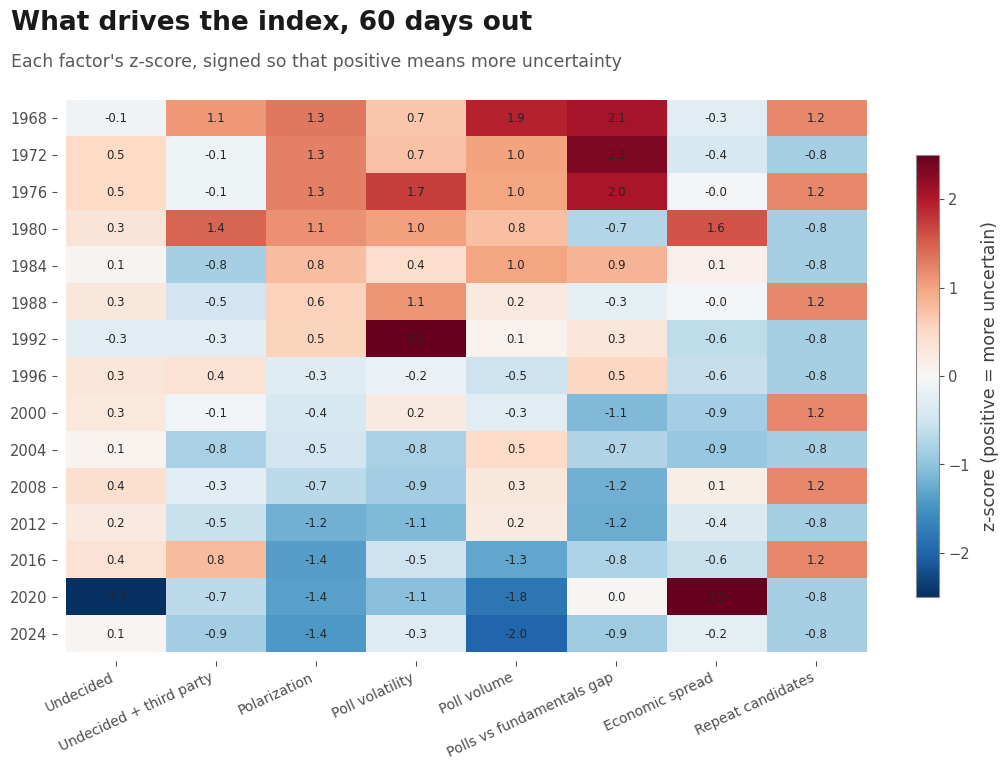

In [32]:
names = {"undecided": "Undecided", "undecided_third": "Undecided + third party", "polarization": "Polarization",
         "volatility": "Poll volatility", "volume": "Poll volume", "gap": "Polls vs fundamentals gap",
         "econ_spread": "Economic spread", "repeat_candidates": "Repeat candidates"}
z = pd.DataFrame([{"cycle": r.cycle, **U.index_value(r, ucal["standardization"])[1]}
                  for _, r in uh[uh.days_left == 60].iterrows()]).set_index("cycle").rename(columns=names)
fig, ax = figure("What drives the index, 60 days out",
                 "Each factor's z-score, signed so that positive means more uncertainty", width=11, height=7.5)
im = ax.imshow(z.values, cmap="RdBu_r", vmin=-2.5, vmax=2.5, aspect="auto")
ax.set_xticks(range(z.shape[1]), z.columns, rotation=25, ha="right", fontsize=10); ax.set_yticks(range(len(z)), z.index)
for i in range(z.shape[0]):
    for j in range(z.shape[1]):
        if pd.notna(z.values[i, j]):
            ax.text(j, i, f"{z.values[i, j]:.1f}", ha="center", va="center", fontsize=8.5, color="0.15")
for s in ax.spines.values():
    s.set_visible(False)
plt.colorbar(im, ax=ax, label="z-score (positive = more uncertain)", shrink=0.8)
plt.show()

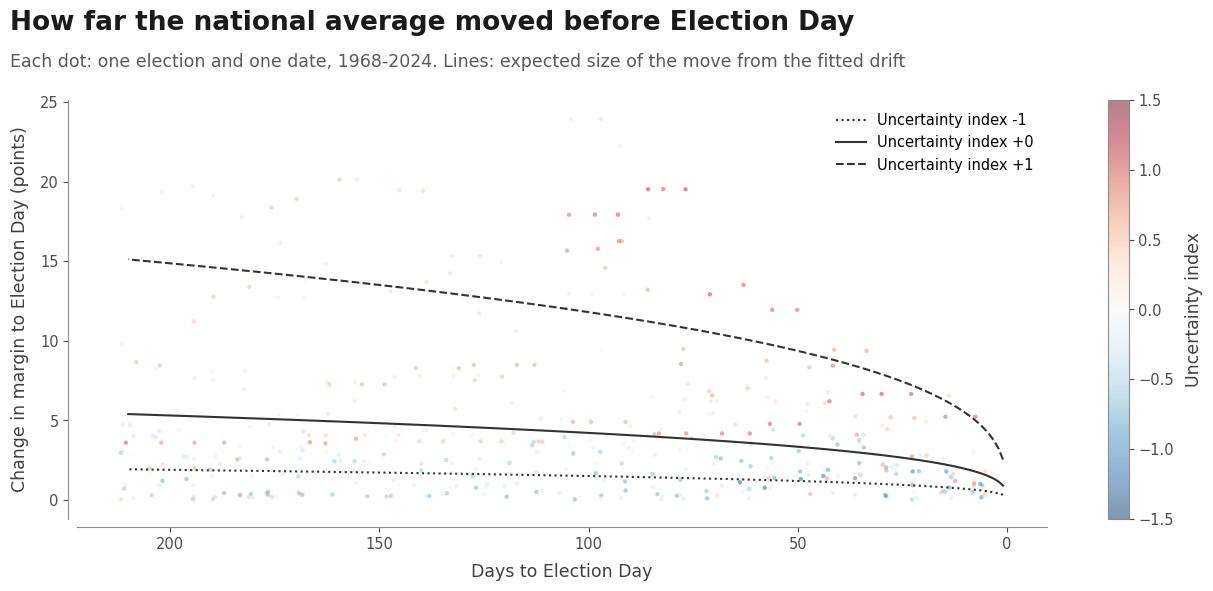

In [33]:
fig, ax = figure("How far the national average moved before Election Day",
                 "Each dot: one election and one date, 1968-2024. Lines: expected size of the move from the fitted drift",
                 height=6)
sc = ax.scatter(ud.days_left + np.random.default_rng(0).uniform(-2, 2, len(ud)), ud.change.abs(), s=10, alpha=0.5,
                c=ud["index"], cmap="RdBu_r", vmin=-1.5, vmax=1.5, lw=0)
d = np.arange(1, 211)
for idx, ls in [(-1, ":"), (0, "-"), (1, "--")]:
    sd = ucal["drift_const"] * d ** (1 / 3) * np.exp(ucal["index_kappa"] * idx)
    ax.plot(d, 0.8 * sd, color="0.2", ls=ls, lw=1.5, label=f"Uncertainty index {idx:+d}")
ax.invert_xaxis(); ax.set_xlabel("Days to Election Day"); ax.set_ylabel("Change in margin to Election Day (points)")
plt.colorbar(sc, ax=ax, label="Uncertainty index"); ax.legend(loc="upper right")
plt.show()

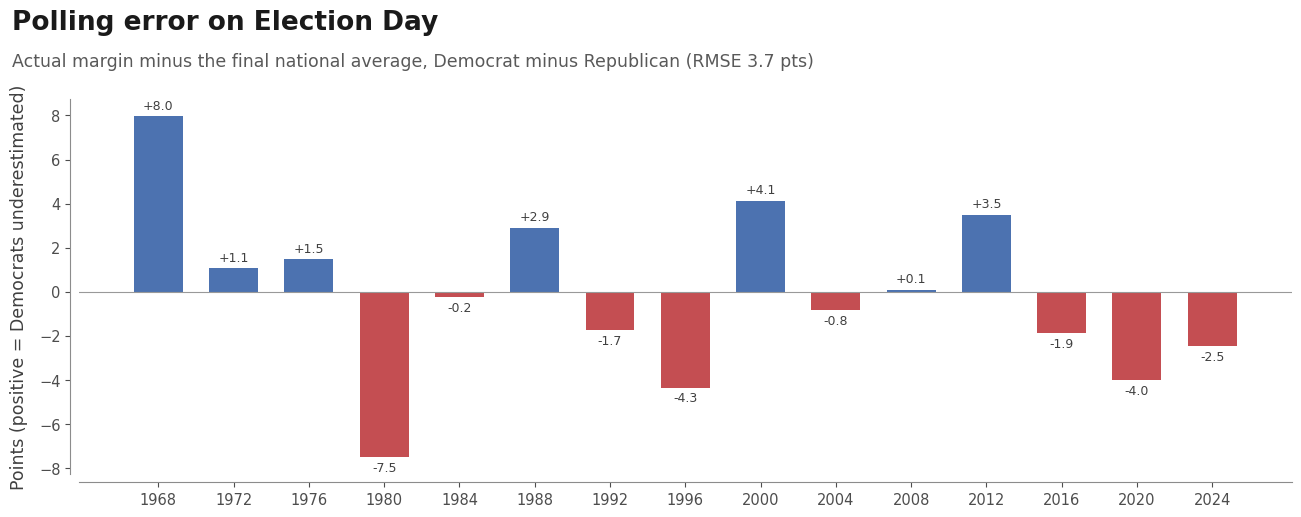

In [34]:
f = ufinal.set_index("cycle")
fig, ax = figure("Polling error on Election Day",
                 f"Actual margin minus the final national average, Democrat minus Republican "
                 f"(RMSE {np.sqrt((f.ed_error ** 2).mean()):.1f} pts)", height=5.5)
bars = ax.bar(f.index, f.ed_error, width=2.6, color=np.where(f.ed_error > 0, "#4C72B0", "#C44E52"))
bar_labels(ax, bars, f.ed_error, "{:+.1f}")
ax.axhline(0, color=GREY, lw=0.8); ax.set_xticks(f.index); ax.set_ylabel("Points (positive = Democrats underestimated)")
plt.show()

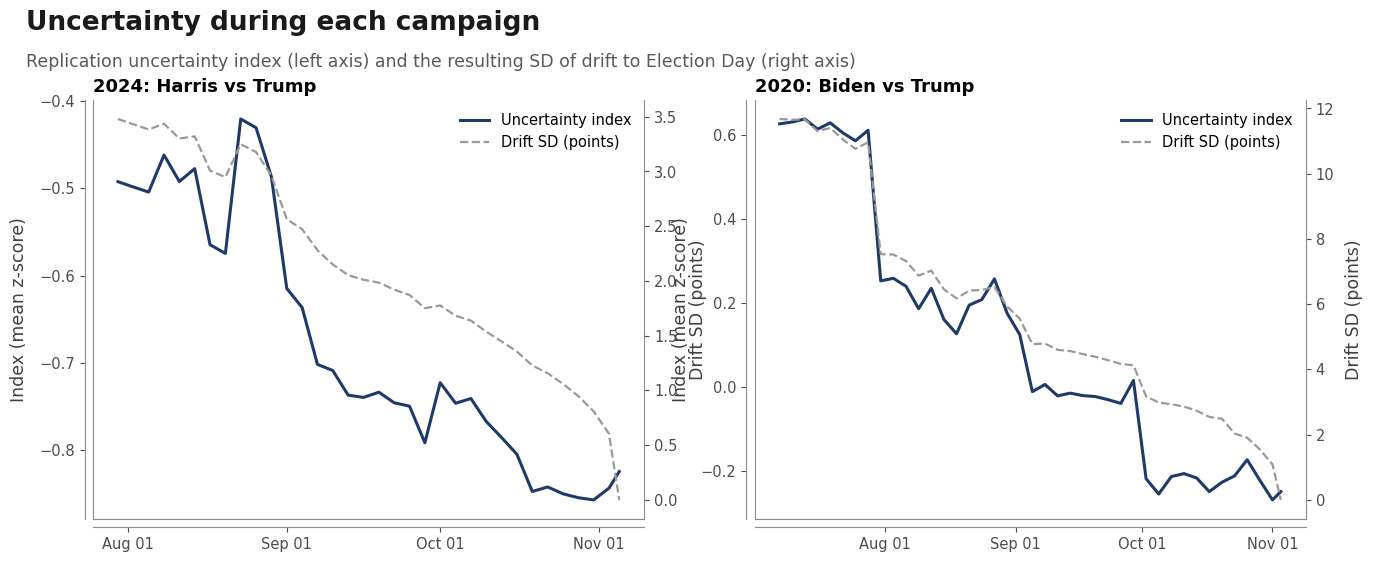

In [35]:
fig, axes = figure("Uncertainty during each campaign",
                   "Replication uncertainty index (left axis) and the resulting SD of drift to Election Day (right axis)", ncols=2)
for ax, c in zip(axes, CY):
    t = ts[c]
    l1 = ax.plot(t.date, t.uncertainty_index, color=REPLICATION, lw=2.2, label="Uncertainty index")
    ax2 = ax.twinx(); ax2.spines["right"].set_visible(True)
    l2 = ax2.plot(t.date, t.sd_drift, color=GREY, lw=1.6, ls="--", label="Drift SD (points)")
    ax.set_title(NAME[c]); ax.set_ylabel("Index (mean z-score)"); ax2.set_ylabel("Drift SD (points)"); dates(ax)
    ax.legend(l1 + l2, [l.get_label() for l in l1 + l2], loc="upper right")
plt.show()

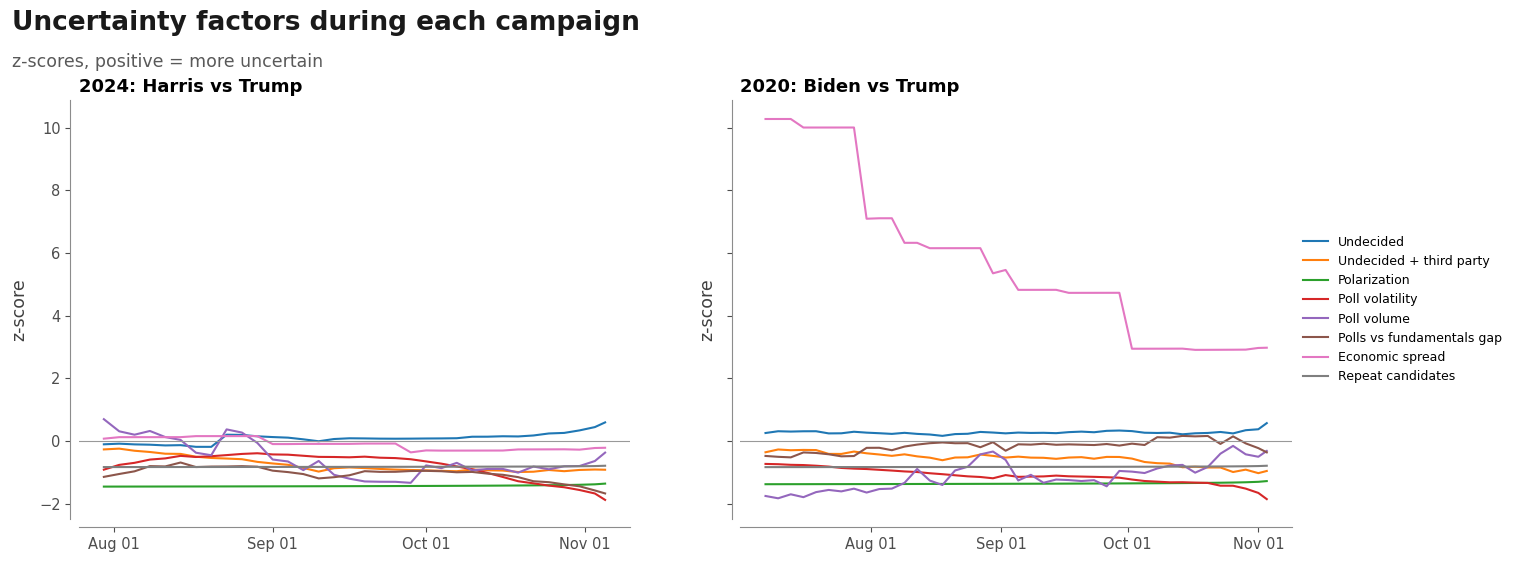

In [36]:
zc = [c for c in ts[2024] if c.startswith("uz_")]
fig, axes = figure("Uncertainty factors during each campaign", "z-scores, positive = more uncertain", ncols=2, sharey=True)
for ax, c in zip(axes, CY):
    t = ts[c].set_index("date")[zc].rename(columns=lambda x: names[x[3:]])
    for col in t:
        ax.plot(t.index, t[col], lw=1.5, label=col)
    ax.axhline(0, color=GREY, lw=0.8); ax.set_title(NAME[c]); ax.set_ylabel("z-score"); dates(ax)
axes[1].legend(loc="center left", bbox_to_anchor=(1.0, 0.5), fontsize=9)
plt.show()

## Not implemented yet

In [37]:
pd.Series(C.NOT_IMPLEMENTED, name="pending").to_frame()

,pending
economist_projection,Projection of economic indicators to Election ...
news_volume,Uncertainty-index factor 'news volume' (count ...
pre1946_proxies,"Before each official series starts, the econom..."
early_polls_1936,Election Day polling error is checked on 1968-...
economic_uncertainty_survey,Uncertainty-index factor 'economic uncertainty...
pit_before_1972,Point-in-time (as first published) economic da...
